## use transfe learning on the  SVO pretrained model to perdict on BVO,CVO

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Lambda, Embedding, BatchNormalization,LSTM, RepeatVector, TimeDistributed, concatenate, Reshape
from tensorflow.keras.losses import mse, binary_crossentropy
from tensorflow.keras import backend as K
from tensorflow.keras.models import load_model
from keras.optimizers import Adam

2025-08-01 16:43:44.108862: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-01 16:43:44.119417: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1754059424.131146  578667 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1754059424.134788  578667 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1754059424.144154  578667 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [2]:
#### read data files CVO


import numpy as np
data_CVO = np.load('dataCVO.npz')
nwarmup_all = data_CVO['nwarupsteps']
print(np.unique(nwarmup_all))

real_sigma_all = data_CVO['realpart_sigma']
img_sigma_all = data_CVO['imgpart_sigma']

real_g0_all = data_CVO['realpart_g0']
img_g0_all = data_CVO['imgpart_g0']

mask_train = np.isin(nwarmup_all,[100000 ,250000] )
mask_test = ~np.isin(nwarmup_all,[100000,250000] )





[100000 150000 200000 250000 300000 350000]


In [3]:
print(mask_test)

[ True  True False False  True  True False False  True False False  True
  True False False False False  True  True  True  True False  True  True
  True  True False  True  True False  True  True False  True  True  True
  True False  True False  True  True False False  True  True  True  True
 False  True  True  True  True False  True  True  True  True  True False
 False  True  True  True  True False  True False False False  True  True
  True  True  True  True  True False  True  True  True False  True  True
  True  True False  True  True  True  True False  True  True  True  True
  True False False  True  True False  True  True  True False  True  True
  True  True False  True False  True False  True  True  True False False
  True  True False False False  True  True False  True False False  True
  True  True  True  True  True  True  True  True  True False False False
  True  True False False  True  True  True False False  True False  True
  True  True  True  True  True False  True  True  T

In [5]:
#preprocess
min = 50000
max = 580000 # these are hardcoded from the SVO nwarmupset
min_max_normal = lambda x: (x-min/(max - min))
all_labels = min_max_normal(nwarmup_all) #nwarmup
X_all = img_g0_all #min_max_normal(img_train)
Y_all = img_sigma_all


In [6]:
trained_model =load_model('trained_model_svo_dataless.keras')


# Freeze some layers to preserve pre-trained knowledge
for layer in trained_model.layers[:4]:  # Example: freezing the entire encoding layer
    layer.trainable = False
trained_model.compile(optimizer='adam', loss='mse')


2025-08-01 16:44:23.245174: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [7]:
trained_model.fit([X_all[mask_train],all_labels[mask_train]],Y_all[mask_train].reshape(-1,Y_all.shape[1] , 1),epochs=30, batch_size=32,validation_split=0.2)

Epoch 1/30
3/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0101  

2025-08-01 16:44:27.597532: E tensorflow/core/util/util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 162ms/step - loss: 0.0123 - val_loss: 0.0067
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0058 - val_loss: 0.0034
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0027 - val_loss: 0.0033
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0021 - val_loss: 0.0030
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0013 - val_loss: 8.3380e-04
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 7.5637e-04 - val_loss: 2.7197e-04
Epoch 8/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 4.0336e-04 - val_loss: 1.2366e-04
Epoch 9/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 2.3867e-04 - val_loss: 5.0251e-05
Epoch 10/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 1.5498e-04 - val_loss: 4.4347e-05
Epoch 11/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.1411e-04 - val_loss: 4.2307e-05
Epoch 12/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step -

In [8]:


#### fine-tune by unfreezing all layers

for layer in trained_model.layers:  # Example: freezing the first two layers
    layer.trainable = True
trained_model.compile(optimizer=Adam(1e-5), loss='mse')
trained_model.fit([X_all[mask_train],all_labels[mask_train]],Y_all[mask_train].reshape(-1,Y_all.shape[1] , 1),epochs=40, batch_size=32,validation_split=0.2)



Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - loss: 6.1140e-05 - val_loss: 3.6591e-05
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 6.7604e-05 - val_loss: 3.3331e-05
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 5.9304e-05 - val_loss: 3.3434e-05
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 5.6212e-05 - val_loss: 3.5866e-05
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 5.8970e-05 - val_loss: 3.3135e-05
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 5.3640e-05 - val_loss: 3.2781e-05
Epoch 7/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 5.8864e-05 - val_loss: 3.4219e-05
Epoch 8/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 6.2327e-05 - val_loss: 3.3033e-05
Epoch 9/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 5.2614e-05 - val_loss: 3.4279e-05
Epoch 10/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 5.6541e-05 - val_loss: 3.4390e-05
Epoch 11/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 5.6550e-05 - val_loss: 3.3807e

In [9]:
Y_pred = trained_model.predict([X_all[mask_test], all_labels[mask_test]])

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


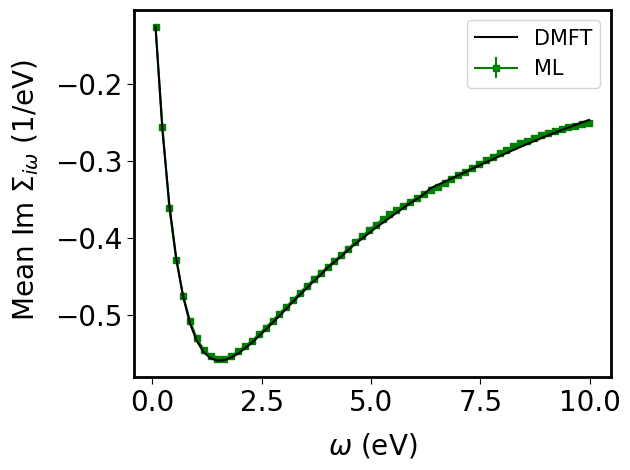

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


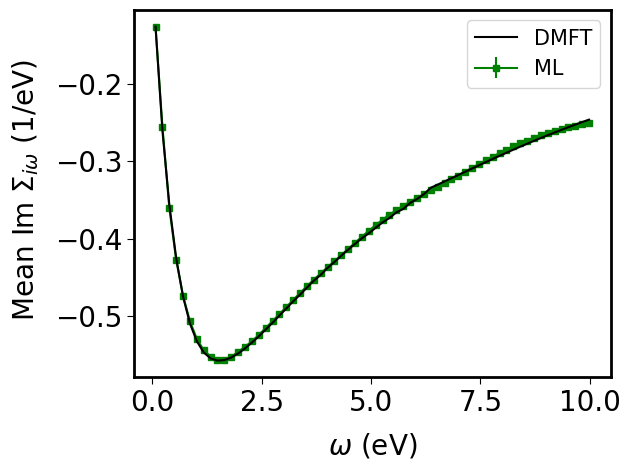

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


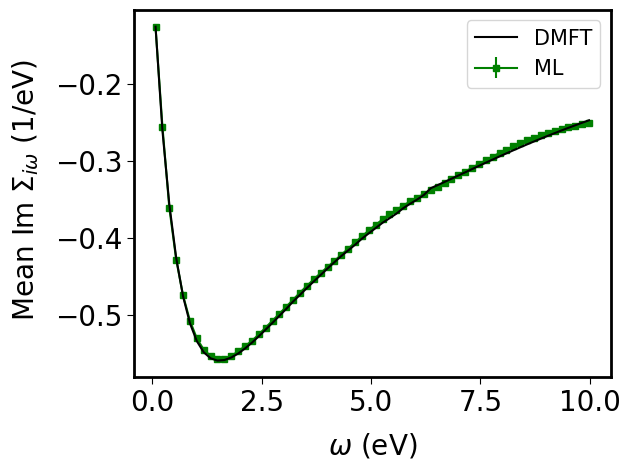

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


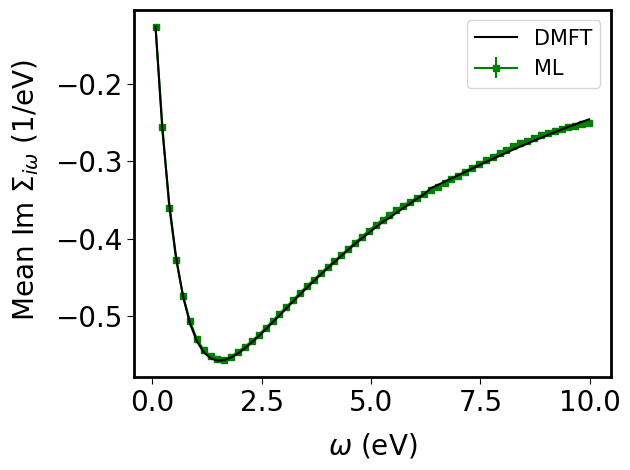

In [13]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica'],
    'font.size': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 10,
    'axes.linewidth': 2.0,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.minor.width': 0.6,
    'ytick.minor.width': 0.6,
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'axes.labelpad': 10
})


y_test = Y_all[mask_test]

nwarmup_labels = nwarmup_all[mask_test]
unique_labels = np.unique(nwarmup_labels)


rms_all=[]

rms= lambda x: np.sqrt(np.mean(x*x))

### frequency
freq=np.linspace(-161,161,2050)
mask = (freq > 0) & (freq < 10)
freq_sel = freq[mask]



'''
for i in range(20):
    error = rms(Y_pred[i] - Y_all[mask_test][i])
    print('nwarmup step, error_rms', nwarmup_all[mask_test][i], error)
    plt.plot(Y_pred[i],'b.-',alpha=0.5,label='prediction')
    plt.plot(Y_all[mask_test][i],'k-',label='MC truth')
    plt.ylabel('Sigma_iw', fontsize=20)
    plt.title(f'Nwarmup step:{nwarmup_all[mask_test][i]}',fontsize=20)
    plt.tight_layout()
    plt.legend()
   # plt.savefig(f'sno_plots/g02iw_{nwarmup_labels[i]}.png')
    plt.show()

'''
#### make avg profile per iteration here

#### plot truth vs prediction avg plot for each unique warmup step
for i in np.arange(len(unique_labels)):
    y_pred_mean = np.mean(Y_pred[nwarmup_labels==unique_labels[i]],axis=0)
    y_truth_mean =  np.mean(y_test[nwarmup_labels==unique_labels[i]],axis=0)
    rms_all.append(rms((y_pred_mean.flatten()-y_truth_mean.flatten())/y_truth_mean.flatten()))
    #rms_all.append(rms((y_pred_mean-y_truth_mean)/y_truth_mean))
    y_pred_std = np.std(Y_pred[nwarmup_labels==unique_labels[i]],axis=0)
    plt.errorbar(freq_sel,y_pred_mean.flatten(),yerr=y_pred_std.flatten(), marker='s',color='green',markersize=5,label='ML')
    #plt.plot(freq_sel,y_pred_mean,'b.-',label='DMFT')
    plt.plot(freq_sel,y_truth_mean,'k-',label='DMFT',zorder=3)
    plt.ylabel(r' Mean Im $\Sigma_{i\omega}$ (1/eV)', fontsize=20)
    plt.xlabel('$\omega$ (eV)',fontsize=20)
    
    plt.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig(f'new_plots/TL_CVO_prediction_new_{unique_labels[i]}.eps',format='eps',dpi=600,bbox_inches='tight')
    plt.show()
#np.save('TL_CVO_new2.npy',np.array([unique_labels,rms_all]))

In [ ]:
print(rms_all)

In [ ]:
data_svo = np.load('dataSVO.npz')

for i in np.arange(500):
    plt.plot(data_svo['imgpart_sigma'][i],'b-',label='SVO')
    plt.plot(data_SNO['imgpart_sigma'][i],'r-',label='SNO')
    #plt.plot(data_SMO['imgpart_sigma'][i],'g-',label='SNO')
    plt.title('Sigma_iw plots',fontsize=20)
#plt.savefig('sigma_iw_sno_svo.png')   
plt.show()

In [ ]:
for i in np.arange(500):
    plt.plot(data_svo['imgpart_g0'][i],'b-',label='SVO')
    plt.plot(data_SNO['imgpart_g0'][i],'r-',label='SNO')
    #plt.plot(data_SMO['imgpart_g0'][i],'g-',label='SNO')
    plt.ylim(-0.6,0)
    plt.title('G0 plots',fontsize=20)
#plt.savefig('g0_sno_svo.png')   
plt.show()